Feature Scaling
Standardization and Normalization

In [1]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
#load the dataset taianic dataset by using seaborn
df = sns.load_dataset("titanic")

In [4]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [5]:
df.shape

(891, 15)

In [6]:
df.columns.tolist()


['survived',
 'pclass',
 'sex',
 'age',
 'sibsp',
 'parch',
 'fare',
 'embarked',
 'class',
 'who',
 'adult_male',
 'deck',
 'embark_town',
 'alive',
 'alone']

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB


In [8]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [12]:
df2=df[["survived",	"pclass"	,"age","parch"]]
df2.head()

,survived,pclass,age,parch
0,0,3,22.0,0
1,1,1,38.0,0
2,1,3,26.0,0
3,1,1,35.0,0
4,0,3,35.0,0


In [16]:
df3=df2.fillna(df2.mean())

In [17]:
X=df3.drop("survived",axis=1)
y=df3["survived"]

In [18]:
print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nX columns:", X.columns.tolist())
print("\ny value counts:\n", y.value_counts())

X shape: (891, 3)
y shape: (891,)

X columns: ['pclass', 'age', 'parch']

y value counts:
 survived
0    549
1    342
Name: count, dtype: int64


Split first, scale second.

Prevent data leakage — the scaler must see only training data when computing mean/std/min/max.

In [19]:
from sklearn.model_selection import train_test_split

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [21]:
print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("y_train:", y_train.shape, " y_test:", y_test.shape)
print("\ny_train distribution:\n", y_train.value_counts(normalize=True).round(3))
print("\ny_test  distribution:\n", y_test.value_counts(normalize=True).round(3))

X_train: (712, 3)  X_test: (179, 3)
y_train: (712,)  y_test: (179,)

y_train distribution:
 survived
0    0.617
1    0.383
Name: proportion, dtype: float64

y_test  distribution:
 survived
0    0.615
1    0.385
Name: proportion, dtype: float64


 Standardization — Fit on Train Only

StandardScaler on X_train, then transform both.

The scaler stores training mean and std. Those same values are reused for the test set — no leakage.

In [22]:
from sklearn.preprocessing import StandardScaler

In [23]:
std_scaler = StandardScaler()


In [31]:
X_train_sc=X_train_std = std_scaler.fit_transform(X_train)   # fit + transform

In [32]:
X_test_sc=X_test_std  = std_scaler.transform(X_test)        # transform ONLY

In [26]:
print("Learned means :", np.round(std_scaler.mean_, 3))
print("Learned stds  :", np.round(std_scaler.scale_, 3))

Learned means : [ 2.309 29.787  0.39 ]
Learned stds  : [ 0.833 13.006  0.838]


In [37]:
X_train_sc

array([[ 0.82956755, -0.00674143, -0.46618317],
       [-0.37094484, -0.00674143, -0.46618317],
       [-1.57145722, -0.00674143, -0.46618317],
       ...,
       [ 0.82956755,  1.40037135,  3.11571343],
       [-1.57145722,  1.32348365, -0.46618317],
       [-1.57145722, -0.00674143, -0.46618317]], shape=(712, 3))

In [43]:
X_train_sc=pd.DataFrame(X_train_sc,columns=["pclass"	,"age","parch"])
X_test_sc=pd.DataFrame(X_test_sc,columns=["pclass"	,"age","parch"])

In [44]:
X_train_sc.head()

,pclass,age,parch
0,0.829568,-0.006741,-0.466183
1,-0.370945,-0.006741,-0.466183
2,-1.571457,-0.006741,-0.466183
3,0.829568,-0.906260,0.727782
4,-0.370945,0.093280,0.727782


In [42]:
X_train_sc.describe().round(2)

,pclass,age,parch
count,712.00,712.00,712.00
mean,0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-1.57,-2.26,-0.47
25%,-0.37,-0.60,-0.47
50%,0.83,-0.01,-0.47
75%,0.83,0.48,-0.47
max,0.83,3.86,6.70


In [45]:
X_test_sc.describe().round(2)

,pclass,age,parch
count,179.00,179.00,179.00
mean,-0.00,-0.03,-0.05
std,1.02,1.00,0.79
min,-1.57,-2.23,-0.47
25%,-0.97,-0.44,-0.47
50%,0.83,-0.01,-0.47
75%,0.83,0.25,-0.47
max,0.83,3.09,1.92


 Normalization (Min-Max) — Fit on Train Only

In [46]:
from sklearn.preprocessing import MinMaxScaler

In [49]:
mm_scaler = MinMaxScaler()
X_train_norm = mm_scaler.fit_transform(X_train)
X_test_norm  = mm_scaler.transform(X_test)

In [50]:
print("Learned mins:", np.round(mm_scaler.data_min_, 3))
print("Learned maxs:", np.round(mm_scaler.data_max_, 3))

Learned mins: [-1.571 -2.258 -0.466]
Learned maxs: [0.83  3.861 6.698]


In [51]:
X_train_norm=pd.DataFrame(X_train_norm,columns=["pclass"	,"age","parch"])
X_test_norm=pd.DataFrame(X_test_norm,columns=["pclass"	,"age","parch"])

In [52]:
X_train_norm.head()

,pclass,age,parch
0,1.0,0.367921,0.000000
1,0.5,0.367921,0.000000
2,0.0,0.367921,0.000000
3,1.0,0.220910,0.166667
4,0.5,0.384267,0.166667


In [53]:
X_train_norm.describe()

,pclass,age,parch
count,712.000000,712.000000,712.000000
mean,0.654494,0.369022,0.065075
std,0.416782,0.163548,0.139689
min,0.000000,0.000000,0.000000
25%,0.500000,0.271174,0.000000
50%,1.000000,0.367921,0.000000
75%,1.000000,0.447097,0.000000
max,1.000000,1.000000,1.000000


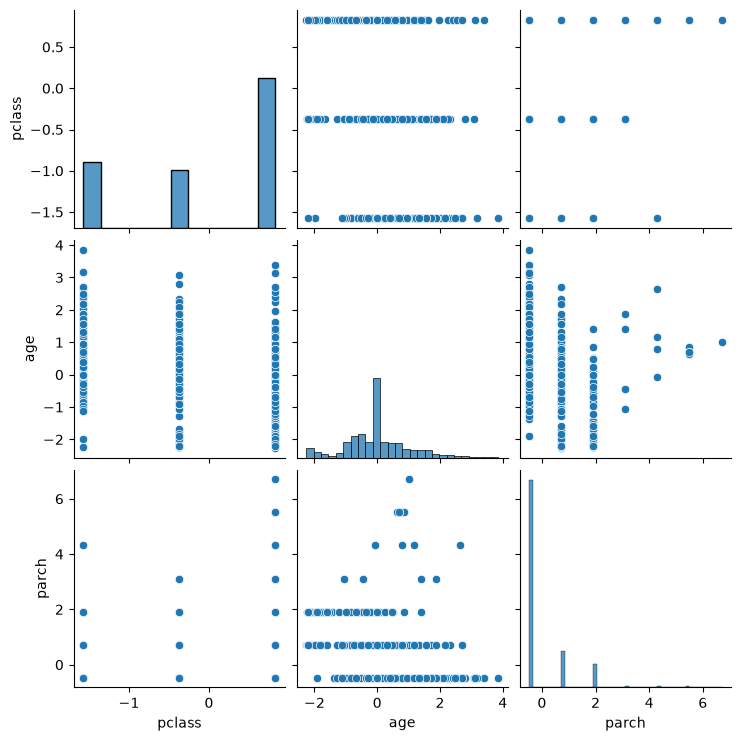

In [56]:
sns.pairplot(X_train_sc)

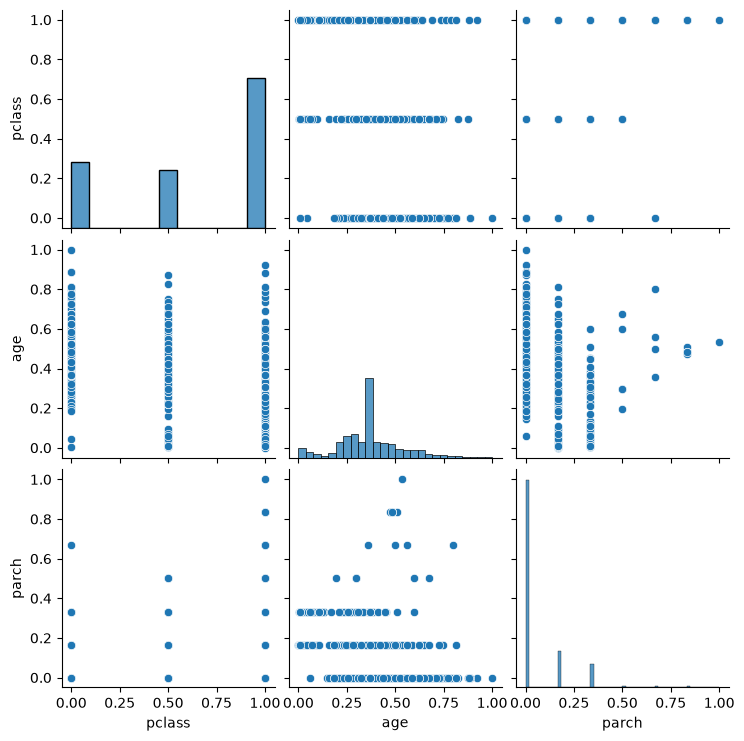

In [57]:
sns.pairplot(X_train_norm)